# 7 · A luma residual upscaler

The eye resolves fine detail in brightness (luma) far better than in colour - which is why
video sends colour at a quarter of the resolution and nobody notices. This model spends
all of its work on brightness:

- **Colour is bicubic.** The bicubic skip makes the whole picture, as in
  `3_upscale_web.ipynb`, and the network never changes the colour.
- **The network corrects brightness only**, with residual blocks: a deeper body inside the
  same 4-pixel halo.

Steps:

1. **Data** - load the patch pairs.
2. **Model** - bicubic as a fixed convolution, plus a learned brightness correction.
3. **Speed** - is it fast enough for a live stream? Checked before training.
4. **Train** - and compare with bicubic after every epoch.
5. **Save** - write a checkpoint, check it loads back the same, run a whole frame.
6. **Export** - float32 and float16 at the client's tile, float16 as a whole frame.

Needs: `0_data_preprocess.ipynb`. Results: `summary.md`, "The luma residual model".

In [1]:
"""Settings."""

import copy

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

from helpers import metrics, models, speed, tiles, training, webexport
from helpers.training import DATA_DIR, DEVICE

CHECKPOINT = training.CHECKPOINT_DIR / "upscale_luma.pt"
FRAME_DIR = DATA_DIR / "synthetic"

# The network (see "2. Model")
WIDTHS = (24,)    # channels of the plain convolutions before the blocks
BLOCKS = 2           # residual blocks, at the last width
STEM = 3             # kernel size of the first convolution
SKIP = 5             # kernel size of the bicubic skip (bicubic x2 needs 4 taps; 5 is the smallest odd size)
LUMA_IN = False      # True: the body reads Y alone instead of R, G and B
MAX_EPOCHS = 500     # a safety limit; training stops once it has converged
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
SEED = 0

BENCH_RESOLUTIONS = [(480, 270), (640, 360), (960, 540), (1280, 720)]   # LR input sizes
BENCH_LR_SIZE = (320, 180)
BENCH_BATCHES = [1, 2, 4, 8, 16]
STEP_WIDTH, STEP_HEIGHT = 320, 180       # LR pixels one client tile adds to the picture (notebook 5)
FRAME_WIDTH, FRAME_HEIGHT = 1920, 1080   # the whole-frame graph
NAME = "luma_24x2"

training.seed_everything(SEED)

## 1. Data

`train` is what the model learns from, with random flips and rotations as free extra
examples. `val` is held out: every score below is measured on it.

The LR patches carry a halo of extra pixels, so the model's output is a bit too large;
`trim` cuts that border off before the loss and the scores.

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 8 frames each
train  11117 patches from 697 sources
val     2369 patches from 149 sources
lr batch (32, 3, 72, 72)  hr batch (32, 3, 128, 128)


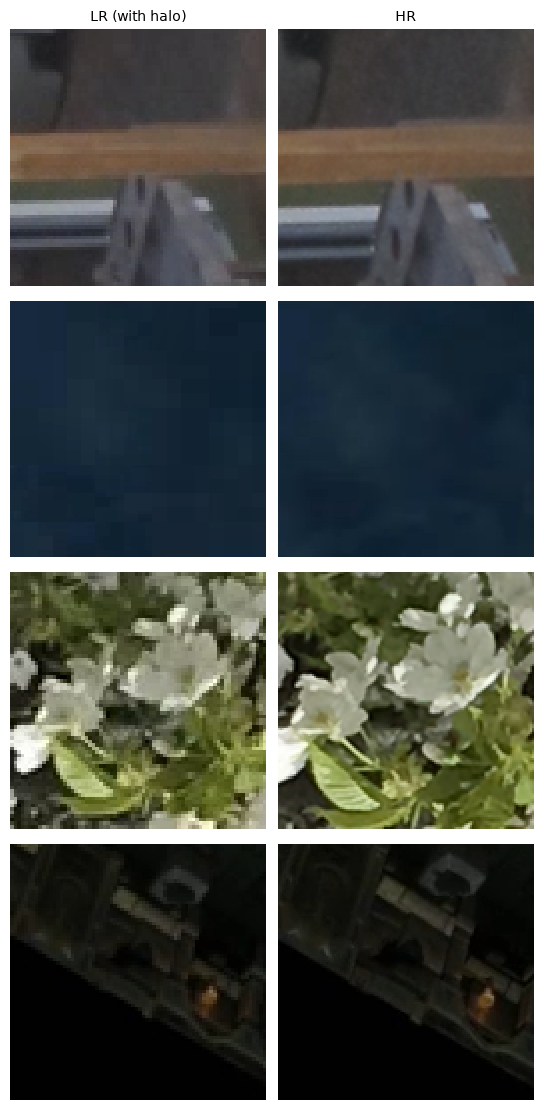

In [2]:
manifest = training.load_manifest()
training.describe(manifest)
SCALE = manifest["scale"]
train_loader, val_loader = training.loaders(DATA_DIR, manifest, BATCH_SIZE)
trim = training.trimmer(manifest)

lr_batch, hr_batch = next(iter(train_loader))
print("lr batch", tuple(lr_batch.shape), " hr batch", tuple(hr_batch.shape))
training.show_patches({"LR (with halo)": lr_batch[:4], "HR": hr_batch[:4]})

## 2. Model

    LR --> bicubic skip (fixed 5x5 conv) ----------------------------------------------+
    LR --> conv 3x3 -> ReLU -> residual block x2 -> output conv 3x3 -> same value for R, G, B --+--> add --> PixelShuffle --> HR

- **Brightness only.** The output convolution makes one correction for each of the
  `scale²` HR pixels of an LR pixel, and the same value is added to R, G and B. In BT.709
  that moves Y by exactly that value and leaves Cb and Cr as bicubic made them: the colour
  cannot drift, and nothing is spent on detail the eye barely sees.
- **Residual blocks.** Each is 3x3 -> ReLU -> 1x1, with its input added back. The 1x1
  reaches no further, so a block costs one pixel of halo, and adding the input back keeps
  a deeper body easy to train.
- **Starts as bicubic.** The output convolution starts at zero, as in `3_upscale_web.ipynb`.
  The body reads R, G and B.

**Halo.** The stem reaches 1, every 3x3 after it 1: 4 in all, within the halo of
the patches and of the client's tiles.

In [3]:
model = models.LumaUpscaler(WIDTHS, BLOCKS, STEM, SKIP, SCALE, LUMA_IN).to(DEVICE)
assert model.halo <= manifest["halo"], "the model reaches further than the patches' halo"
print(model)
print(f"{models.count_parameters(model, learned_only=True):,} learned parameters, halo {model.halo}, "
      f"{speed.macs_per_lr_pixel(model):,.0f} multiply-adds per LR pixel")

# Colour is untouched: even with random weights, what the network adds has no Cb or Cr
probe = copy.deepcopy(model)
with torch.no_grad():
    for weight in probe.parameters():
        if weight.requires_grad:
            weight.normal_(0, 0.1)
    x = torch.rand(2, 3, 40, 40, device=DEVICE)
    change = metrics.rgb_to_yuv(probe(x) - probe.shuffle(probe.skip(x)))
print(f"largest colour change with random weights: {change[:, 1:].abs().max().item():.1e} (float32 rounding)")

LumaUpscaler(
  (skip): BicubicSkip(
    (conv): Conv2d(3, 12, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
  )
  (shuffle): PixelShuffle(upscale_factor=2)
  (body): Sequential(
    (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): ResidualBlock(
      (conv): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (point): Conv2d(24, 24, kernel_size=(1, 1), stride=(1, 1))
    )
    (3): ResidualBlock(
      (conv): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (point): Conv2d(24, 24, kernel_size=(1, 1), stride=(1, 1))
    )
  )
  (tail): Conv2d(24, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
)


13,156 learned parameters, halo 4, 13,932 multiply-adds per LR pixel
largest colour change with random weights: 1.2e-07 (float32 rounding)


In [4]:
"""Before training: the model must score exactly like bicubic."""

bicubic = models.Resize(SCALE).to(DEVICE)
baseline = training.evaluate(bicubic, val_loader, trim)
start = training.evaluate(model, val_loader, trim)
metrics.print_table({"bicubic": baseline, "untrained model": start})
assert abs(start["rgb"] - baseline["rgb"]) < 1e-3, "the model should start as bicubic"

                     wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic              37.30    36.38    47.06    47.27     35.00   0.9135
untrained model      37.30    36.38    47.06    47.27     35.00   0.9135


## 3. Speed - is it fast enough?

A model that misses the frame time is no use for a live stream, however good it looks.
Speed depends on the network's shape, not its weights, so it is checked before training:
if it is too slow, change `WIDTHS` and `BLOCKS` now.

A batch of one is the honest number - frames arrive one at a time. A larger batch is
cheaper per frame, but each frame waits for the others.

In [5]:
"""One frame at a time, at the sizes a client asks for."""

model.eval()
print(f"{'output':>12}{'ms/frame':>10}   fits")
with torch.no_grad():
    for width, height in BENCH_RESOLUTIONS:
        x = torch.rand(1, 3, height, width, device=DEVICE)
        ms = speed.time_ms(lambda: model(x), seconds=1.0)
        print(f"{f'{width * SCALE}x{height * SCALE}':>12}{ms:10.1f}   {speed.frame_budget(ms)}")

      output  ms/frame   fits


     960x540       0.9   60 fps


    1280x720       1.5   60 fps


   1920x1080       3.3   60 fps


   2560x1440       5.9   60 fps


In [6]:
"""What a batch buys at 320x180 -> 640x360."""

per_frame = {}
with torch.no_grad():
    for batch in BENCH_BATCHES:
        x = torch.rand(batch, 3, BENCH_LR_SIZE[1], BENCH_LR_SIZE[0], device=DEVICE)
        per_frame[batch] = speed.time_ms(lambda: model(x), seconds=1.0) / batch

print(f"{'batch':>5}{'ms/frame':>10}{'vs batch 1':>12}")
for batch, ms in per_frame.items():
    print(f"{batch:5}{ms:10.2f}{per_frame[1] / ms:11.2f}x")

batch  ms/frame  vs batch 1
    1      0.43       1.00x
    2      0.40       1.06x
    4      0.39       1.11x
    8      0.39       1.11x
   16      0.38       1.13x


### On the target hardware

Spec sheets state compute in **TOPS** (10¹² operations per second; a multiply-add is 2).
`webexport.count_work` counts the operations and the memory traffic in the ONNX graph of
one client tile (640x360 out, plus the halo); a frame costs that times its tiles.

The runtime is a **roofline** estimate: a device needs at least *operations / peak
compute* and at least *bytes / bandwidth*, whichever is slower. This computer's GPU is
timed to see what share of its peak it reaches, and every device in `speed.HARDWARE` is
assumed to reach the same share. A browser usually reaches less, so read it as a best
case; the benchmark page, opened on the device, gives the real number.

In [7]:
"""The work in one client tile, counted in its ONNX graph, and the TOPS a stream needs."""

plan = tiles.plan_tiling((1920, 1080), scale=SCALE, halo=model.halo)
tile_shape = plan["input"][2:]   # (height, width) of one tile, halo included
# into checkpoints/, not dist/, so the benchmark page does not list it
tile_graph = webexport.export(model, "speed_check_luma.onnx", tile_shape, halo=model.halo,
                              models_dir=training.CHECKPOINT_DIR / "speed")
work = webexport.count_work(tile_graph["path"])
ops_per_pixel = work["operations"] / work["input_pixels"]   # every convolution keeps the size
bytes_per_pixel = work["activation_bytes"] / work["input_pixels"]
print(f"one {tile_shape[1]}x{tile_shape[0]} tile: {work['operations'] / 1e9:.2f} G operations, "
      f"{work['activation_bytes'] / 1e6:.0f} MB of activations moved, {work['weight_bytes'] / 1e3:.0f} KB of weights")
for op, operations in work["by_op"].items():
    print(f"  {op:<13}{operations / 1e9:8.3f} G  ({operations / work['operations']:.1%})")
print(f"per LR pixel: {ops_per_pixel:,.0f} operations, {bytes_per_pixel:,.0f} bytes moved")


def frame_work(width, height):
    """Operations and bytes for one width x height output frame, cut into the client's tiles."""
    plan = tiles.plan_tiling((width, height), scale=SCALE, halo=model.halo)
    pixels = plan["runs"] * plan["input"][2] * plan["input"][3]   # LR pixels computed, halos included
    return {"runs": plan["runs"], "operations": pixels * ops_per_pixel,
            "bytes": pixels * bytes_per_pixel + plan["runs"] * work["weight_bytes"]}


print(f"\n{'output':>11}{'tiles':>7}{'G ops/frame':>13}{'TOPS at 30 fps':>16}{'TOPS at 60 fps':>16}")
for width, height in BENCH_RESOLUTIONS:
    frame = frame_work(width * SCALE, height * SCALE)
    print(f"{f'{width * SCALE}x{height * SCALE}':>11}{frame['runs']:>7}{frame['operations'] / 1e9:>13.1f}"
          f"{frame['operations'] * 30 / 1e12:>16.3f}{frame['operations'] * 60 / 1e12:>16.3f}")

one 328x188 tile: 1.73 G operations, 156 MB of activations moved, 56 KB of weights
  Conv            1.726 G  (99.5%)
  Relu            0.004 G  (0.3%)
  Add             0.004 G  (0.2%)
  Concat          0.000 G  (0.0%)
  DepthToSpace    0.000 G  (0.0%)
per LR pixel: 28,120 operations, 2,536 bytes moved

     output  tiles  G ops/frame  TOPS at 30 fps  TOPS at 60 fps
    960x540      2          3.9           0.116           0.233
   1280x720      4          6.9           0.208           0.416
  1920x1080      9         15.6           0.468           0.936
  2560x1440     16         27.7           0.832           1.665


In [8]:
"""Simulated runtime per frame on the target hardware (float32)."""

# Calibrate: the share of its peak this GPU reaches, on one whole 1080p frame (no tiles)
if DEVICE.type == "cuda":
    x = torch.rand(1, 3, 540, 960, device=DEVICE)
    with torch.no_grad():
        measured_ms = speed.time_ms(lambda: model.eval()(x), seconds=1.0)
    whole_frame = {"operations": 960 * 540 * ops_per_pixel,
                   "bytes": 960 * 540 * bytes_per_pixel + work["weight_bytes"]}
    best_ms, _ = speed.roofline_ms(whole_frame, *speed.HARDWARE[speed.THIS_GPU])
    efficiency = best_ms / measured_ms
    print(f"{speed.THIS_GPU}: measured {measured_ms:.2f} ms per 1080p frame, the roofline says at least "
          f"{best_ms:.2f} ms, so it reaches {efficiency:.0%} of its peak "
          f"({whole_frame['operations'] / (measured_ms / 1000) / 1e12:.1f} TOPS)")
else:
    efficiency = 1.0
    print("no GPU here to calibrate on: the estimates below are the roofline itself, a best case")
cpu_ms = webexport.time_graph(tile_graph["path"], tile_shape)
print(f"this CPU (onnxruntime): {cpu_ms:.1f} ms per tile, {work['operations'] / (cpu_ms / 1000) / 1e12:.3f} TOPS")

resolutions = [(width * SCALE, height * SCALE) for width, height in BENCH_RESOLUTIONS]
print(f"\nestimated ms per frame at {efficiency:.0%} of the peak (c = compute-bound, m = memory-bound)")
print(f"{'':<36}" + "".join(f"{f'{width}x{height}':>14}" for width, height in resolutions) + "   1080p")
for name, (tflops, gbps) in speed.HARDWARE.items():
    row = f"{name:<36}"
    for width, height in resolutions:
        best_ms, limit = speed.roofline_ms(frame_work(width, height), tflops, gbps)
        row += f"{best_ms / efficiency:>10.1f} ({limit[0]})"
    full_hd_ms = speed.roofline_ms(frame_work(1920, 1080), tflops, gbps)[0] / efficiency
    print(f"{row}   {speed.frame_budget(full_hd_ms)}")

NVIDIA RTX 3090: measured 3.32 ms per 1080p frame, the roofline says at least 1.40 ms, so it reaches 42% of its peak (4.4 TOPS)


this CPU (onnxruntime): 4.1 ms per tile, 0.419 TOPS

estimated ms per frame at 42% of the peak (c = compute-bound, m = memory-bound)
                                           960x540      1280x720     1920x1080     2560x1440   1080p
Intel UHD 620 (laptop iGPU)               21.8 (c)      39.0 (c)      87.8 (c)     156.1 (c)   under 30 fps
Intel Iris Xe, 96 EU (laptop iGPU)        12.2 (m)      21.7 (m)      48.9 (m)      87.0 (m)   under 30 fps
Apple M1, 8-core GPU                      12.2 (m)      21.7 (m)      48.9 (m)      87.0 (m)   under 30 fps
NVIDIA GTX 1650                            6.5 (m)      11.6 (m)      26.0 (m)      46.2 (m)   30 fps
NVIDIA RTX 3060                            2.3 (m)       4.1 (m)       9.2 (m)      16.4 (m)   60 fps
NVIDIA RTX 3090                            0.9 (m)       1.6 (m)       3.6 (m)       6.3 (m)   60 fps


## 4. Train

Same recipe as `2_upscale_nn.ipynb`: the loss is `metrics.ssim_l1_loss` (0.84 x (1 - SSIM
on luma) + 0.16 x L1 on RGB), and after every epoch the epoch with the best luma SSIM
(`ssim-y`) is kept. Training runs until the score stops improving, halving the learning
rate at every plateau; `MAX_EPOCHS` is only a safety limit.

The colour columns (`psnr-u`, `psnr-v`) stay exactly at bicubic's: only brightness moves.

Training until the model stops improving, at most 500 epochs. Untrained model: val_ssim_y: 0.9135.
Learning rate 1.0e-03, halved after 6 epochs without improvement; training stops when 1.0e-05 does not help either.
Epoch 1/500


26/347 [==>...........................] - 1s 20ms/step - loss: 0.1369

65/347 [=====>........................] - 1s 16ms/step - loss: 0.1156

102/347 [========>.....................] - 2s 15ms/step - loss: 0.1110

140/347 [============>.................] - 2s 15ms/step - loss: 0.1101

...

202/347 [=================>............] - 3s 13ms/step - loss: 0.0865

243/347 [=====================>........] - 3s 13ms/step - loss: 0.0856

283/347 [========================>.....] - 4s 13ms/step - loss: 0.0861

324/347 [============================>.] - 4s 13ms/step - loss: 0.0862

347/347 [==============================] - 5s 14ms/step - loss: 0.0864 - val_wpsnr: 38.1161 - val_psnr_y: 37.2719 - val_psnr_u: 47.0927 - val_psnr_v: 47.3035 - val_psnr_rgb: 35.5923 - val_ssim_y: 0.9281 - learning_rate: 1.0e-05
Epoch 108: val_ssim_y did not improve from 0.9282 (6 of 6 epochs without improvement)
Epoch 108: stopping (converged - no improvement in 6 epochs, even at the smallest learning rate)
Restoring model weights from the end of the best epoch: 102 (val_ssim_y: 0.9282, +0.0147 over the untrained model). Training took 108 epochs, 8.9 min.


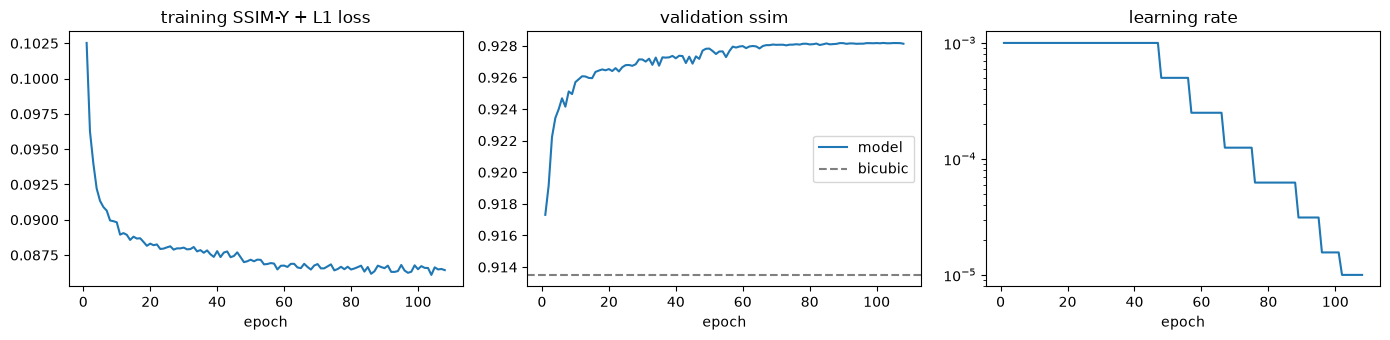

                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic             37.30    36.38    47.06    47.27     35.00   0.9135   +0.0000 ssim-y vs bicubic
model               38.13    37.29    47.09    47.30     35.62   0.9282   +0.0147 ssim-y vs bicubic


In [9]:
history, best = training.train(model, train_loader, val_loader, trim, MAX_EPOCHS,
                               learning_rate=LEARNING_RATE, loss_fn=metrics.ssim_l1_loss, select="ssim")
training.plot_history(history, baseline, key="ssim", loss_name="SSIM-Y + L1 loss")

final = training.evaluate(model, val_loader, trim)
metrics.print_table({"bicubic": baseline, "model": final},
                    extra=lambda name, s: f"   {s['ssim'] - baseline['ssim']:+.4f} ssim-y vs bicubic")

### What it looks like

Check text lines and window edges - that is what a desktop stream is made of.

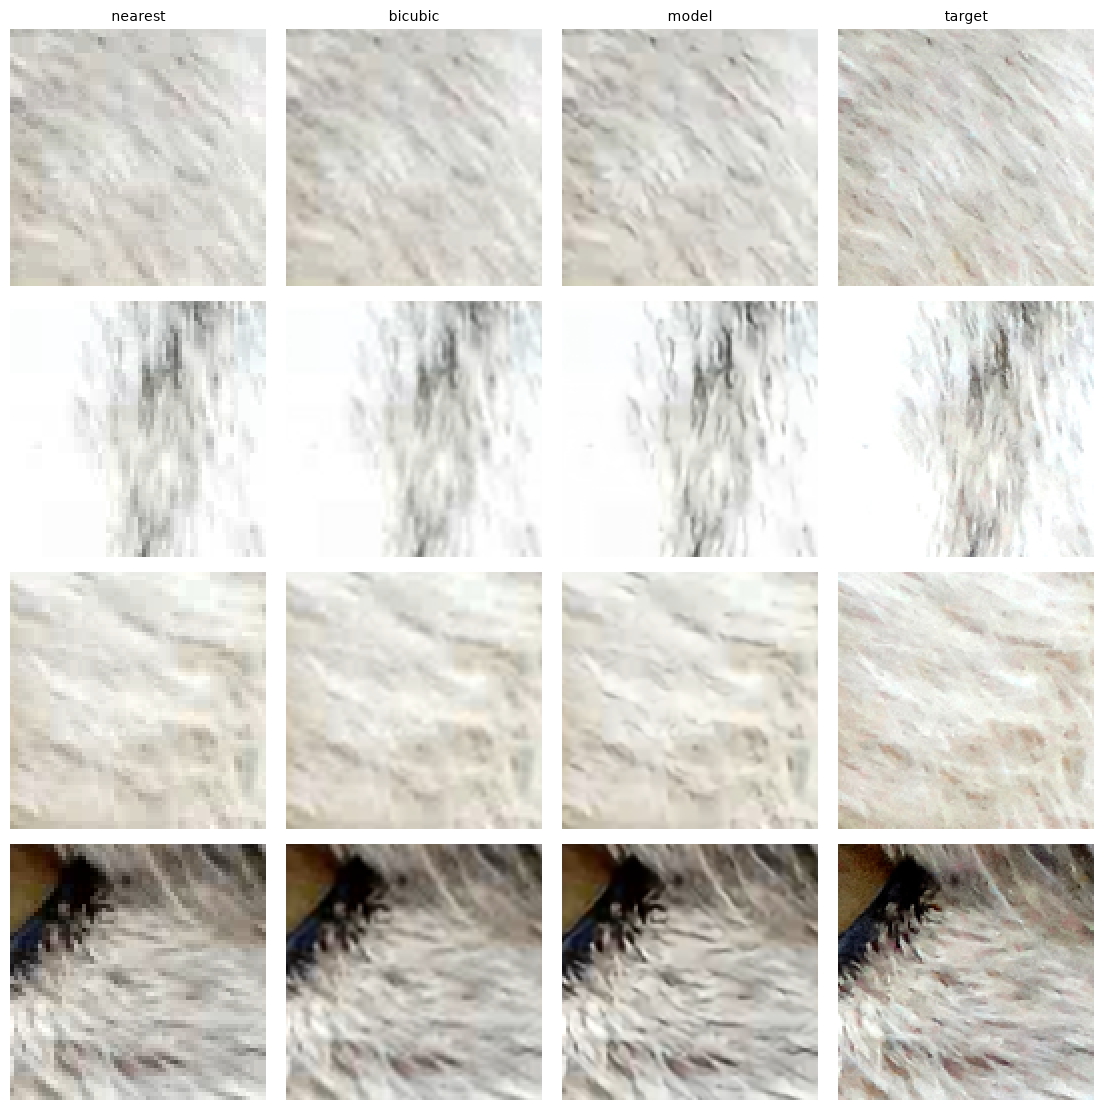

In [10]:
lr, hr = next(iter(val_loader))
lr, hr = lr[:4].to(DEVICE), hr[:4].to(DEVICE)
with torch.no_grad():
    training.show_patches({
        "nearest": trim(F.interpolate(lr, scale_factor=SCALE, mode="nearest")),
        "bicubic": trim(models.bicubic(lr, SCALE)),
        "model": trim(model.eval()(lr)),
        "target": hr,
    })

## 5. Save and reload

The checkpoint holds the weights *and* everything needed to rebuild the model. We load
it into a fresh model and check it computes the same thing.

In [11]:
training.save_checkpoint(CHECKPOINT, model, architecture="LumaUpscaler", widths=list(WIDTHS),
                         blocks=BLOCKS, stem=STEM, skip=SKIP, luma_in=LUMA_IN, scale=SCALE,
                         halo=model.halo, loss="ssim_l1_loss", select="ssim", epochs=len(history),
                         best_epoch=best["epoch"], val=final, val_bicubic=baseline,
                         degradation=manifest["degradation"])

checkpoint = training.load_checkpoint(CHECKPOINT)
loaded = models.LumaUpscaler(tuple(checkpoint["widths"]), checkpoint["blocks"], checkpoint["stem"],
                             checkpoint["skip"], checkpoint["scale"], checkpoint["luma_in"]).to(DEVICE)
loaded.load_state_dict(checkpoint["state_dict"])
training.assert_same_model(model, loaded)
print("reloaded model is identical")

saved /home/henrik/desktop-streamer-ai/src/upscale/checkpoints/upscale_luma.pt (62 KB)
reloaded model is identical


### A whole frame

The model is fully convolutional, so it runs on a picture of any size, not only patches.

                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic             25.82    25.09    29.55    29.01     23.92   0.9437
model               27.53    27.07    29.57    29.01     25.12   0.9648


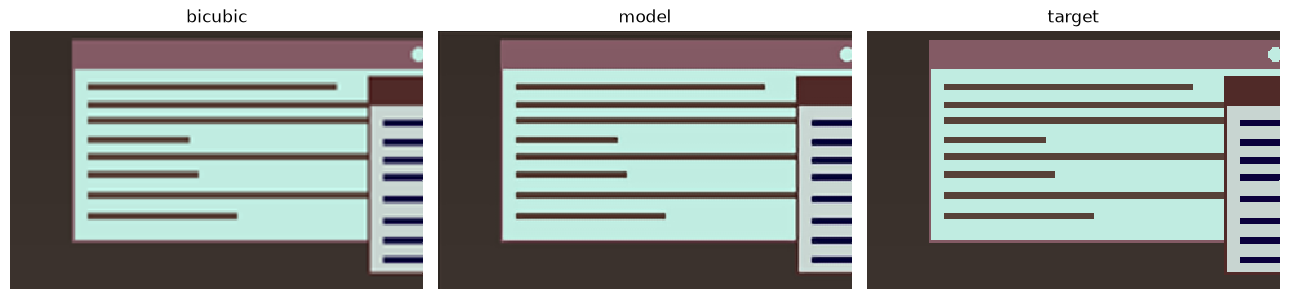

In [12]:
truth = Image.open(sorted(FRAME_DIR.glob("*.png"))[0]).convert("RGB")
truth = truth.crop((0, 0, truth.width - truth.width % SCALE, truth.height - truth.height % SCALE))
small = truth.resize((truth.width // SCALE, truth.height // SCALE), Image.BICUBIC)

with torch.no_grad():
    upscaled = loaded.eval()(training.to_tensor(small))
target = training.to_tensor(truth)
metrics.print_table({"bicubic": metrics.report(models.bicubic(training.to_tensor(small), SCALE), target),
                     "model": metrics.report(upscaled, target)})
Image.fromarray(training.to_image(upscaled)).save(training.SAMPLE_DIR / "upscaled_luma.png")

box = (slice(0, 200), slice(0, 320))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
panels = {"bicubic": np.asarray(small.resize(truth.size, Image.BICUBIC)),
          "model": training.to_image(upscaled), "target": np.asarray(truth)}
for ax, (name, image) in zip(axes, panels.items()):
    ax.imshow(image[box], interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 6. Export for the browser

At the tile a client runs (a 320x180 step, `5_upscale_geometry.ipynb`), so it compares
with `6_upscale_reparam.ipynb` and the static filters on the page: float32, float16 (half
the size), and float16 as one whole 1080p frame. Each graph is checked against the torch
model first. It is `Conv`, `Relu`, `Add`, `Concat` and `DepthToSpace` - all inside the
browser's fast operator set.

In [13]:
def input_shape(step_height, step_width, halo):
    """The model input for a step: the step plus the halo on every side, as (height, width)."""
    return (step_height + 2 * halo, step_width + 2 * halo)


def check_and_time(info, shape, dtype, tolerance):
    """Check a written graph against the loaded model, time it on the CPU, print one line."""
    webexport.check_graph(info["path"], loaded, np.random.rand(1, 3, *shape).astype(np.float32), dtype, tolerance)
    ms = webexport.time_graph(info["path"], shape, dtype)
    webexport.annotate(info, cpu_ms=round(ms, 2))
    print(webexport.summary_line(info, ms))


tile_name = f"tile{STEP_WIDTH}x{STEP_HEIGHT}"
halo = checkpoint["halo"]
tile_shape = input_shape(STEP_HEIGHT, STEP_WIDTH, halo)
frame_shape = input_shape(FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, halo)

fp32 = webexport.export(loaded, f"upscale_{NAME}_{tile_name}.onnx", tile_shape, label=f"{NAME} fp32", halo=halo)
check_and_time(fp32, tile_shape, np.float32, tolerance=2e-3)

fp16 = webexport.to_float16(fp32, f"upscale_{NAME}_fp16_{tile_name}.onnx")
webexport.write_metadata(fp16["path"], {"label": f"{NAME} fp16"})
check_and_time(fp16, tile_shape, np.float16, tolerance=4e-3)

frame = webexport.to_frame(fp16, f"upscale_{NAME}_fp16_{tile_name}_frame.onnx", FRAME_WIDTH, FRAME_HEIGHT)
check_and_time(frame, frame_shape, np.float16, tolerance=4e-3)
print("compare in a browser: uv run src/upscale/benchmark/main.py")

upscale_luma_24x2_tile320x180.onnx                     57.6 KB    4.42 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3


upscale_luma_24x2_fp16_tile320x180.onnx                31.0 KB    4.31 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3


upscale_luma_24x2_fp16_tile320x180_frame.onnx          31.0 KB   52.38 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
compare in a browser: uv run src/upscale/benchmark/main.py
